# IND320 – Compulsory work, part 4

- GitHub: https://github.com/maryanahmed11011-pixel/IND320.prosjekt.maryan
- Streamlit app: https://ind320prosjektmaryan-lmvbjxajmrnrqkykq8ivne.streamlit.app/
- Screencast: *(link added when the video is ready)*

This notebook builds on parts 1–3. Part 4 adds exchange rates from Norges
Bank, a check of time zones across the data sources, forecasting of
reservoir filling with River, and a refactored Streamlit app with dynamic
Plotly plots, an interactive map and a new page structure.

## AI usage

*TODO: write a short description of how AI was used in part 4
(what it generated, what you wrote, tested and decided yourself).*

## Log

*TODO: 300–500 words about the work on part 4, covering both the
notebook and the Streamlit app, including which bonus task was chosen.*

## 1. App structure (sketch)

Before changing the code, the pages were organised by **type of task**,
following the assignment's suggestion:

- **Overview:** the front page and the new interactive map, which is
  also where an area is selected.
- **Explore:** the data sources themselves – reservoir data (the
  `LineChartColumn` table and the plot page are merged into one data
  overview page), cross-border flows and exchange rates.
- **Analyse:** STL and spectrogram, weather anomalies (SATV/SPC and LOF)
  and the new sliding window correlation between weather and reservoirs.
- **Predict:** the new forecasting page.

The sidebar keeps two global selections in `st.session_state`: the
**area** (also set by clicking in the map) and the **time period**
(shared by the map and the forecast). Each menu group gets its own
colour, so it is clear which part of the app is active.

![Planned app structure](figures/app_structure.png)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("..")  # the notebook is in notebooks/, the app code in the root

import theme  # noqa: F401  shared colours (also the matplotlib style)
from analysis import fetch_exchange_rates
from theme import COLORS

## 2. Exchange rates from Norges Bank

Norges Bank has an open SDMX API with no key. A series is identified by
a key such as `B.EUR+USD.NOK.SP`: business-day frequency (`B`), the
base currencies EUR and USD (`+` fetches several in one call), quoted in
NOK, spot rates (`SP`). The function `fetch_exchange_rates` in
`analysis.py` asks for CSV, picks the date, currency and value columns,
corrects for currencies quoted per 100 units, and returns one column per
currency in NOK per unit. The same function will be used in the app.

In [2]:
# EUR and USD for 2024 (the same year as the weather data for NO3)
rates = fetch_exchange_rates(("EUR", "USD"), start="2024-01-01",
                             end="2024-12-31")
print(rates.shape[0], "business days")
rates.head()

251 business days


,EUR,USD
date,,
2024-01-02,11.2815,10.2971
2024-01-03,11.3200,10.3672
2024-01-04,11.2845,10.3027
2024-01-05,11.3090,10.3553
2024-01-08,11.3620,10.3800


In [3]:
# Quick check: summary per currency and the number of missing days
print(rates.describe().round(3))
print("Missing values:", rates.isna().sum().to_dict())

           EUR      USD
count  251.000  251.000
mean    11.628   10.743
std      0.192    0.244
min     11.268   10.297
25%     11.448   10.546
50%     11.668   10.694
75%     11.771   10.950
max     12.111   11.423
Missing values: {'EUR': 0, 'USD': 0}


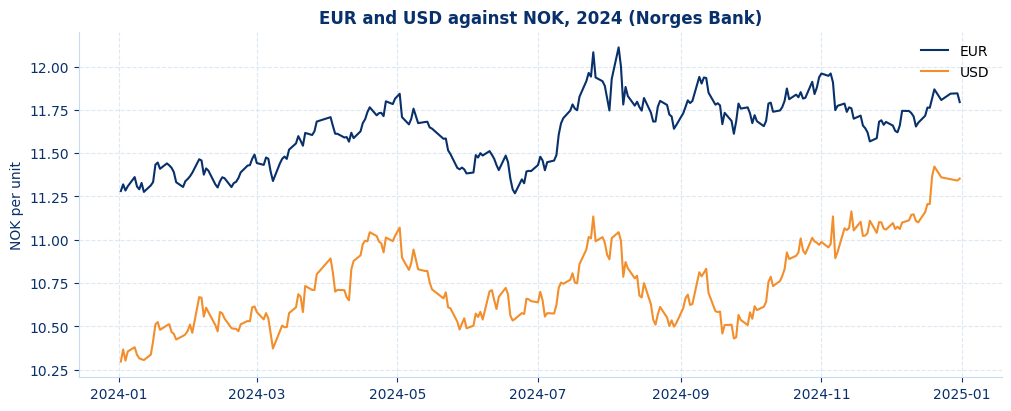

In [4]:
# Both rates over 2024. Weekends and Norwegian holidays have no rate,
# so the lines only have points on business days.
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.plot(rates.index, rates["EUR"], color=COLORS["dark"], label="EUR")
ax.plot(rates.index, rates["USD"], color=COLORS["accent"], label="USD")
ax.set(ylabel="NOK per unit", title="EUR and USD against NOK, 2024 "
       "(Norges Bank)")
ax.legend()
plt.show()

Both rates move largely together, since much of the variation comes from
the krone itself: when NOK weakens, both EUR and USD become more
expensive. In 2024 one euro cost between 11.27 and 12.11 NOK (mean
11.63) and one dollar between 10.30 and 11.42 NOK (mean 10.74). Both
rates rose in spring, fell back in June and had a short peak in early
August. Towards the end of the year the two rates drift apart: the euro
stays around 11.7–11.8 NOK, while the dollar rises clearly and ends the
year near its maximum. The dollar is also slightly more volatile
(standard deviation 0.24 vs. 0.19 NOK). The data are business days only
(251 days, no missing values), so weekends and holidays must be filled
or skipped before the rates are combined with daily or hourly data.

## 3. Time zones in the data sources

The four sources are combined later (correlation, forecasting), so their
time stamps must mean the same thing. Norway uses CET (UTC+1) in winter
and CEST (UTC+2) in summer, so a naive mix of UTC and local time shifts
data by one or two hours, and can move values across a day or week
boundary. Each source is checked below.

### 3.1 Magasinstatistikk (NVE)

Weekly values with a date (`dato_Id`), ISO year and ISO week, but no time
of day or time zone. The check below shows which weekday the date falls
on, and whether it belongs to the ISO week given in the data.

In [5]:
import numpy as np
import requests

from analysis import (ERA5_URL, LOCAL_TZ, daily_to_weekly, download_era5,
                      hourly_to_daily, utc_to_local)

RES_URL = ("https://biapi.nve.no/magasinstatistikk/api/"
           "Magasinstatistikk/HentOffentligData")
res = pd.DataFrame(requests.get(RES_URL, timeout=30).json())
res["dato_Id"] = pd.to_datetime(res["dato_Id"])

# Which weekday is the date, and does it match the ISO week in the data?
iso = res["dato_Id"].dt.isocalendar()
print("Weekdays of dato_Id:", res["dato_Id"].dt.day_name().value_counts().to_dict())
print("Date matches iso_aar/iso_uke:",
      ((iso["year"] == res["iso_aar"]) & (iso["week"] == res["iso_uke"])).mean())

# Publication time of the next update (no time zone given)
pub = pd.to_datetime(res["neste_Publiseringsdato"], errors="coerce")
pub = pub[pub.dt.year > 2000]  # 0001-01-01 is used for "no date"
print("Next publication:", pub.max(), "-", pub.max().day_name())

Weekdays of dato_Id: {'Sunday': 14967}
Date matches iso_aar/iso_uke: 1.0
Next publication: 2026-11-25 13:00:00 - Wednesday


All 14 967 dates are Sundays, and every date lies in the ISO week given
by `iso_aar` and `iso_uke`. A weekly value therefore describes the week
Monday–Sunday and is dated on its last day. The next publication is
given as a local Norwegian time without offset (Wednesday 13:00), so new
data for a week arrives three days after the week has ended. This lag
matters for forecasting: the newest known week is always the previous
one.

### 3.2 ERA5 from open-meteo

The weather data is downloaded with `timezone=GMT`, so the hourly time
stamps are UTC. According to the open-meteo documentation, a named time
zone is applied as **one fixed UTC offset**, resolved at request time.
Asking for `Europe/Oslo` would therefore not follow the switch to and
from summer time, which is why the project asks for UTC and converts
afterwards. The cells below download two days around each switch for
one point (Trondheim) and compare the two options.

In [6]:
# One point, three days around each summer-time switch in 2024.
# The switch day is in the middle: the first and last local day are
# partial, because a UTC download starts 1-2 hours before local midnight.
point = pd.DataFrame({"lat": [63.43], "lon": [10.39]})
spring = download_era5(point, "2024-03-30", "2024-04-01").set_index("time")
autumn = download_era5(point, "2024-10-26", "2024-10-28").set_index("time")

# UTC: always 24 hours per day
print("Hours per UTC day (spring):",
      spring.groupby(spring.index.date).size().tolist())

# Converted to local time: the switch days get 23 and 25 hours
for name, df, day in [("spring", spring, "2024-03-31"),
                      ("autumn", autumn, "2024-10-27")]:
    local = utc_to_local(df[["temperature_2m"]])
    n = local.loc[day].shape[0]
    print(f"Hours on the local switch day {day} ({name}): {n}")

Hours per UTC day (spring): [24, 24, 24]
Hours on the local switch day 2024-03-31 (spring): 23
Hours on the local switch day 2024-10-27 (autumn): 25


In [7]:
# The same request with timezone=Europe/Oslo: which offset is used?
params = {"latitude": 63.43, "longitude": 10.39, "start_date": "2024-03-30",
          "end_date": "2024-03-31", "hourly": "temperature_2m",
          "models": "era5", "timezone": LOCAL_TZ}
oslo = requests.get(ERA5_URL, params=params, timeout=60).json()
print("utc_offset_seconds:", oslo["utc_offset_seconds"],
      "| first and last time stamp:", oslo["hourly"]["time"][0],
      oslo["hourly"]["time"][-1], "| hours:", len(oslo["hourly"]["time"]))

utc_offset_seconds: 3600 | first and last time stamp: 2024-03-30T00:00 2024-03-31T23:00 | hours: 48


The request with `timezone=Europe/Oslo` returned one fixed offset of
3600 s (UTC+1) and 48 time stamps from 00:00 to 23:00 on both days. The
switch to summer time at 02:00 on 31 March is ignored, so every local
time after the switch is one hour wrong. The offset also depends on when
the request is made: run in summer, the same request would use UTC+2 for
the whole period. Requesting UTC and converting with `utc_to_local`
avoids both problems and gives 23 and 25 hours on the switch days.

Precipitation in ERA5 from open-meteo is the sum over the **preceding**
hour, so the value stamped 00:00 belongs to the day before. Converting
to local time shifts this boundary by one or two hours, which is small
compared to daily and weekly sums.

### 3.3 ENTSO-E (cross-border flows, part 2)

In part 2 the hourly flows were queried with start and end in
Europe/Oslo time, converted to **UTC**, and aggregated to days with
Spark (`F.to_date("time")` with the Spark session in UTC). A "day" in
MongoDB is therefore a UTC day, which is 01:00–01:00 local time in
winter and 02:00–02:00 in summer. The pure pandas example below shows
what this does at the start and end of the downloaded period.

In [8]:
# Hours of the downloaded period (local time), as stored (UTC)
hours = pd.date_range("2024-01-01", "2026-01-01", freq="h",
                      tz=LOCAL_TZ, inclusive="left").tz_convert("UTC")
per_utc_day = pd.Series(1, index=hours).groupby(hours.date).sum()
print("First UTC days:", per_utc_day.head(2).to_dict())
print("Last UTC day:", per_utc_day.tail(1).to_dict())

First UTC days: {datetime.date(2023, 12, 31): 1, datetime.date(2024, 1, 1): 24}
Last UTC day: {datetime.date(2025, 12, 31): 23}


The output confirms this: the first hour of 2024 (00:00–01:00 local) ends up as a one-hour
"day" on 31 December 2023, and the last UTC day of 2025 has only 23
hours. In the app, this showed up as an extra year 2023 with almost no
energy in the year selector on the cross-border page. `load_flows` in
`utils.py` now leaves out days before 1 January 2024.

**Solution:** aggregate on local days instead, i.e. in Spark
`F.to_date(F.from_utc_timestamp("time", "Europe/Oslo"))`, or with
`hourly_to_daily` in pandas. The daily data is only used for overviews
in this project, so the one-to-two-hour shift does not change any
conclusions, but it matters if flows are later compared day by day with
weather or prices.

### 3.4 Norges Bank (exchange rates)

The API returns one value per **Norwegian business day**, as a date
without time. According to Norges Bank, the rates are a snapshot taken
at 14:15 CET and published around 16:00 CET. Weekends and Norwegian
public holidays have no rate.

In [9]:
# Weekdays in the exchange rates from section 2
print("Weekdays:", rates.index.day_name().value_counts().to_dict())

# Weekdays in 2024 without a rate = Norwegian public holidays
weekdays = pd.bdate_range("2024-01-01", "2024-12-31")
print("Weekdays without a rate:",
      [d.strftime("%a %d %b") for d in weekdays.difference(rates.index)])

Weekdays: {'Tuesday': 52, 'Wednesday': 50, 'Friday': 50, 'Monday': 50, 'Thursday': 49}
Weekdays without a rate: ['Mon 01 Jan', 'Thu 28 Mar', 'Fri 29 Mar', 'Mon 01 Apr', 'Wed 01 May', 'Thu 09 May', 'Fri 17 May', 'Mon 20 May', 'Tue 24 Dec', 'Wed 25 Dec', 'Thu 26 Dec']


There are rates only on Monday–Friday (251 days in 2024). Of the 262
weekdays in 2024, 11 have no rate: the ten Norwegian public holidays
that fell on a weekday (1 January, Maundy Thursday, Good Friday, Easter
Monday, 1 May, Ascension Day, 17 May, Whit Monday, 25 and 26 December)
and Christmas Eve, when Norges Bank does not publish rates. The rates
follow the Norwegian calendar, not UTC, and need no time zone
conversion. When combined with daily data, missing days must be skipped
or filled (e.g. with the previous business day's rate); for weekly means
they are simply left out.

### 3.5 Summary and solution

| Source | Resolution | Time stamp | Time zone |
|---|---|---|---|
| Magasinstatistikk | weekly | Sunday ending the ISO week | none (Norwegian calendar) |
| ERA5 / open-meteo | hourly | start of hour (precipitation: sum of preceding hour) | UTC (requested with GMT) |
| ENTSO-E (MongoDB) | daily (from hourly) | UTC day | UTC |
| Norges Bank | business days | date, snapshot 14:15 CET | Norwegian calendar |

**Common reference:** local Norwegian calendar days, and ISO weeks ending
on Sunday, labelled with the Sunday's date like Magasinstatistikk.
Three helper functions in `analysis.py` do the conversion, and they will
be used in the correlation and forecasting parts:

- `utc_to_local`: naive UTC → Europe/Oslo (handles summer time).
- `hourly_to_daily`: hourly UTC → local days (precipitation summed,
  other variables averaged); drops partial days at the edges.
- `daily_to_weekly`: days or business days → weeks ending on Sunday.

In [10]:
# Example: NO3 weather (section 2 has 2024 for one point; here the same
# point for the whole year) and exchange rates on the reservoir week grid
weather = download_era5(point, "2024-01-01", "2024-12-31").set_index("time")
weather = weather.drop(columns="location_id")
weekly_weather = daily_to_weekly(hourly_to_daily(weather))
weekly_rates = daily_to_weekly(rates)

filling_no3 = (res[(res["omrType"] == "EL") & (res["omrnr"] == 3)]
               .set_index("dato_Id")["fyllingsgrad"].sort_index())

combined = (weekly_weather.join(weekly_rates)
            .join(filling_no3.rename("filling_degree"), how="inner"))
print(combined.shape)
combined.head()

(53, 7)


,temperature_2m,precipitation,wind_speed_10m,relative_humidity_2m,EUR,USD,filling_degree
2024-01-07,-7.920549,0.9,12.803442,64.725932,11.29875,10.330575,0.497182
2024-01-14,3.785119,52.1,13.447619,91.238095,11.31326,10.329660,0.476007
2024-01-21,-8.844048,3.6,6.263690,81.000000,11.38740,10.453820,0.441178
2024-01-28,4.153571,37.3,11.378571,80.982143,11.40186,10.473680,0.428328
2024-02-04,2.867262,51.2,17.220238,75.029762,11.34956,10.469500,0.423203


All sources now share the same weekly index (Sundays), so they can be
joined without shifting any values: weather as weekly means
(precipitation as weekly sums, e.g. 52 mm in the week ending 14 January),
the exchange rates as weekly means of the business days, and the filling
degree as published. Note that the weather here is for one point only;
in the correlation and forecasting parts the regional averages over the
sampled points are used instead.

## 4. Map areas as GeoJSON

The interactive map in the app needs the areas as GeoJSON. The NVE
shapefiles from part 3 (`geo/budomrader` and `geo/nve_region`) are read
with the same `load_areas` function as before, merged per area
(RØ + RS → VASS1, RM + RN → VASS3), simplified and written to two
GeoJSON files in `geo/`:

- `price_areas.geojson`: NO1–NO5
- `water_areas.geojson`: VASS1–VASS3

Simplifying with a tolerance of 0.01° (about 1 km) removes small details
along the coast that are invisible at country scale, and makes the files
much smaller, so the map loads quickly. Each area also gets a point
inside it (`lon`, `lat`), used for the clickable labels on the map.

In [11]:
import json

from analysis import area_geojson, load_areas, save_area_geojson

GEO_DIR = Path("../geo")

# Size of the shapefiles compared with the simplified GeoJSON files
shp_kb = sum(f.stat().st_size for f in GEO_DIR.rglob("*.shp")) / 1024
paths = save_area_geojson(GEO_DIR)
for path in paths:
    gj = json.loads(path.read_text(encoding="utf-8"))
    print(f"{path.name}: {path.stat().st_size / 1024:.0f} kB,",
          [f["properties"]["region"] for f in gj["features"]])
print(f"Shapefiles (.shp only): {shp_kb:.0f} kB")

price_areas.geojson: 38 kB, ['NO1', 'NO2', 'NO3', 'NO4', 'NO5']
water_areas.geojson: 61 kB, ['VASS1', 'VASS2', 'VASS3']
Shapefiles (.shp only): 1375 kB


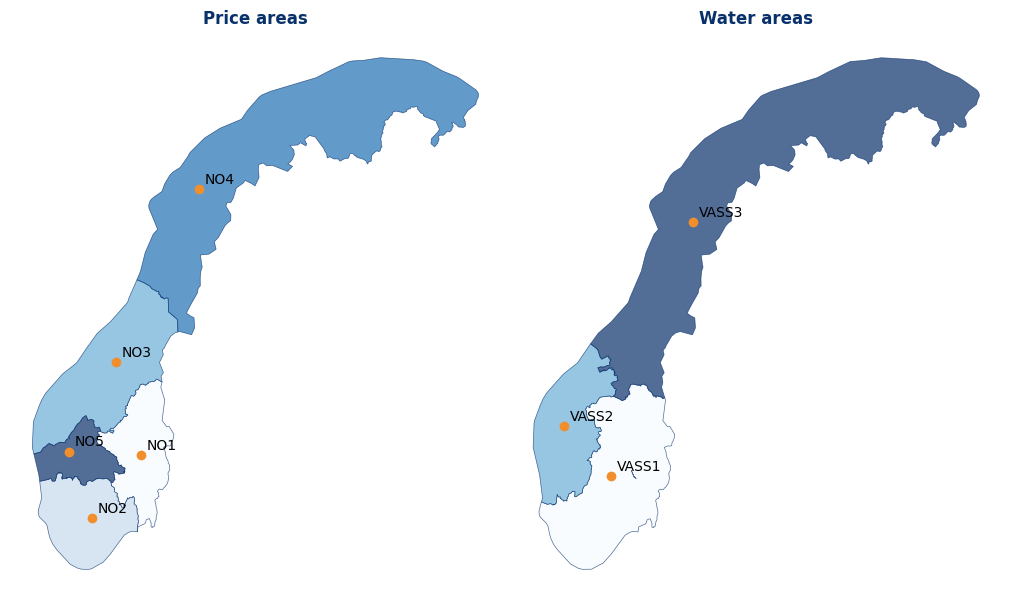

In [12]:
# Quick look at the converted outlines and the label points
import geopandas as gpd

fig, axes = plt.subplots(1, 2, figsize=(10, 6), layout="constrained")
for ax, path in zip(axes, paths):
    gdf = gpd.read_file(path)
    gdf.plot(ax=ax, column="region", cmap="Blues", edgecolor=COLORS["dark"],
             linewidth=0.5, alpha=0.7)
    ax.scatter(gdf["lon"], gdf["lat"], color=COLORS["accent"], zorder=3)
    for _, row in gdf.iterrows():
        ax.annotate(row["region"], (row["lon"], row["lat"]),
                    xytext=(4, 4), textcoords="offset points")
    ax.set_title(path.stem.replace("_", " ").capitalize())
    ax.set_axis_off()
plt.show()

*TODO: comment on the result (file sizes before and after, and whether
the outlines and label points look right).*

## 5. Forecasting reservoir filling with River

*TODO*

## 6. Sliding window correlation: weather vs. reservoirs

*TODO*